# System Migration Reconciliation (legacy engine → new platform, simulated)

Replacing a bank's risk engine is one of the riskiest projects a risk team runs. For weeks the old and new systems value every trade side by side, and every difference has to be explained before anyone signs off. Most differences are harmless noise, and the hard part is finding the real defects hidden among them. This notebook simulates that parallel run and tests which methods find the real breaks.

**What it does.** It reproduces the parallel run that comes before a risk-system migration, such as moving counterparty exposure from a Numerix-style legacy engine to a Murex-style platform.

3,000 swaps are valued in both systems, and static data, MtM, DV01 and PFE are reconciled. Anomaly-detection models then separate genuine breaks from harmless model noise to produce a sign-off pack.

**Data.** Today's SOFR curve and Treasury volatility (U.S. Treasury, FRED). The trade population and both systems' trade records are synthetic, with known defects injected so that detection can be scored.

**Methods.** Two independent Hull–White exposure engines (different curve interpolation, random numbers and market-data feeds) and a DuckDB reconciliation (outer joins, field-level compare, tolerance tests).

Isolation Forest and a PyTorch autoencoder learn the normal shape of valuation differences, and flagged trades are clustered for root-cause analysis.

**Key output.** Matched and unmatched population, static-data breaks, valuation breaks by method with precision and recall by defect type, root-cause clusters, and a sign-off dashboard by book.

## 1. Why migrations need a reconciliation framework

When a bank replaces its exposure engine, the old and new systems run **in parallel** for weeks. Every trade is valued in both, and every difference has to be **explained** before risk management signs off.

Differences fall into four groups:

| Group | Examples | What should happen |
|---|---|---|
| **Population** | trades not migrated, duplicates, wrong ID mapping | fix before anything else |
| **Static data** | notional loaded in thousands, pay/receive flipped, fixed-rate typo, maturity rolled by a period | detectable by field-level compare |
| **Valuation** | missing SOFR fixing, wrong day count on a book, wrong discount curve, wrong volatility mapping | only visible in MtM / DV01 / PFE |
| **Benign** | curve interpolation, Monte Carlo noise, numerical schemes | documented and accepted within tolerance |

The difficulty is in the last two rows. Benign differences make fixed tolerances noisy. Too tight, and thousands of PFE "breaks" are just Monte Carlo noise; too loose, and real defects slip through.

Anomaly detection learns the **normal shape of differences** across all four measures together, and flags the trades that do not fit it.

This notebook simulates the whole exercise with **known injected defects**, so every method can be scored.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import torch

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import QuantLib as ql
import duckdb
from scipy.optimize import least_squares
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score
from sklearn.preprocessing import RobustScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

N_TRADES = 3_000
# per engine (each engine has its own random numbers)
N_PATHS = 2_000
DT = 1 / 12
PFE_QUANTILE = 0.975
SEED = 7
COUNTERPARTIES = [f"Bank {c}" for c in "ABCDEFGH"]
BOOKS = ["ALM hedges", "Issuance hedges", "Client swaps"]
torch.set_num_threads(max(1, (os.cpu_count() or 4) // 2))

print(
    f"QuantLib {ql.__version__} · duckdb {duckdb.__version__} · torch"
    f" {torch.__version__} · run on {dt.date.today():%Y-%m-%d}"
)

QuantLib 1.44 · duckdb 1.5.6 · torch 2.14.1+cu130 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


DEFECT_COLORS = {
    "clean": "#c9c8c3",
    "notional units": PALETTE[0],
    "direction flip": PALETTE[1],
    "rate typo": PALETTE[2],
    "maturity roll": PALETTE[3],
    "missing fixing": PALETTE[4],
    "day-count book": PALETTE[5],
    "wrong curve": PALETTE[6],
    "wrong vol": PALETTE[7],
}

## 3. Market data, curve and Hull–White model

In [3]:
TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/"
    "daily-treasury-rates.csv/{year}/all?type=daily_treasury_yield_curve"
    "&field_tdr_date_value={year}&page&_format=csv"
)


def tenor_in_years(c):
    m = re.match(r"^\s*([\d.]+)\s*(Mo|Month|Yr|Year)", c)
    return (
        None
        if not m
        else float(m.group(1)) / (12 if m.group(2).startswith("Mo") else 1)
    )


def fetch_treasury_par():
    year = dt.date.today().year
    raw = pd.read_csv(
        io.StringIO(
            requests.get(
                TREASURY_URL.format(year=year),
                headers=BROWSER_HEADERS,
                timeout=30,
            ).text
        )
    )
    if raw.empty:
        raw = pd.read_csv(
            io.StringIO(
                requests.get(
                    TREASURY_URL.format(year=year - 1),
                    headers=BROWSER_HEADERS,
                    timeout=30,
                ).text
            )
        )
    raw["date"] = pd.to_datetime(raw["Date"], format="%m/%d/%Y")
    cols = {
        c: tenor_in_years(c)
        for c in raw.columns
        if tenor_in_years(c) is not None
    }
    long = raw.melt(
        id_vars="date",
        value_vars=list(cols),
        var_name="column",
        value_name="par_yield",
    )
    long["tenor"] = long["column"].map(cols)
    return long[["date", "tenor", "par_yield"]].dropna()


par_curves = cached("treasury_par_curves", fetch_treasury_par).pivot(
    index="date", columns="tenor", values="par_yield"
)
EVAL_DATE = par_curves.index.max()
par_today = par_curves.loc[EVAL_DATE].dropna()

VOL_SERIES = {
    "DGS1": 1,
    "DGS2": 2,
    "DGS3": 3,
    "DGS5": 5,
    "DGS7": 7,
    "DGS10": 10,
    "DGS20": 20,
    "DGS30": 30,
}


def fetch_vol_history():
    frames = [
        pd.DataFrame({"date": s.index, "tenor": tenor, "yield": s.values})
        for sid, tenor in VOL_SERIES.items()
        for s in [
            fred.get_series(
                sid, observation_start=EVAL_DATE - pd.Timedelta(days=3 * 365)
            ).dropna()
        ]
    ]
    sofr = fred.get_series(
        "SOFR", observation_start=EVAL_DATE - pd.Timedelta(days=30)
    ).dropna()
    frames.append(
        pd.DataFrame({"date": sofr.index, "tenor": 0.0, "yield": sofr.values})
    )
    return pd.concat(frames, ignore_index=True)


hist = (
    cached("fred_vol_history", fetch_vol_history)
    .pivot(index="date", columns="tenor", values="yield")
    .sort_index()
)
SOFR_TODAY = hist[0.0].dropna().iloc[-1] / 100
yields_hist = hist.drop(columns=0.0).dropna()

# --- Treasury zero curve with QuantLib, then SOFR = Treasury zero + swap
# spread
today = EVAL_DATE.normalize()
ql_today = ql.Date(today.day, today.month, today.year)
ql.Settings.instance().evaluationDate = ql_today
US_GOVT = ql.UnitedStates(ql.UnitedStates.GovernmentBond)
helpers, bond_dc = [], ql.ActualActual(ql.ActualActual.Bond)
for tenor, par_yield in par_today.items():
    y = par_yield / 100
    period = (
        ql.Period(int(round(tenor * 52)), ql.Weeks)
        if tenor < 1
        else ql.Period(int(round(tenor * 12)), ql.Months)
    )
    freq, cpns, px = (
        (ql.Once, [0.0], 100 / (1 + y / 2) ** (2 * tenor))
        if tenor <= 1
        else (ql.Semiannual, [y], 100.0)
    )
    sched = ql.Schedule(
        ql_today,
        US_GOVT.advance(ql_today, period),
        ql.Period(freq),
        US_GOVT,
        ql.Unadjusted,
        ql.Unadjusted,
        ql.DateGeneration.Backward,
        False,
    )
    helpers.append(
        ql.FixedRateBondHelper(
            ql.QuoteHandle(ql.SimpleQuote(px)), 0, 100.0, sched, cpns, bond_dc
        )
    )
ust_curve = ql.PiecewiseConvexMonotoneForward(
    ql_today, helpers, ql.Actual365Fixed()
)
ust_curve.enableExtrapolation()

FINE_T = np.linspace(0, 32, 32 * 365 + 1)
ust_z = np.array(
    [ust_curve.zeroRate(max(t, 1e-4), ql.Continuous).rate() for t in FINE_T]
)
# SOFR OIS minus Treasury par (bp): an explicit, documented swap-spread
# assumption
SWAP_SPREAD_BP = {2: -15, 3: -20, 5: -25, 7: -30, 10: -40, 20: -65, 30: -75}
spread_curve = np.interp(
    FINE_T, list(SWAP_SPREAD_BP), np.array(list(SWAP_SPREAD_BP.values())) / 1e4
)


class DiscountCurve:
    """
    A SOFR discount curve stored as continuous zero rates on a fine daily grid.
    """

    def __init__(self, zero):
        self.zero = np.asarray(zero, dtype=float)
        self.log_df = -self.zero * FINE_T

    def P0(self, t):
        """Discount factor P^M(0, t)."""
        return np.exp(np.interp(t, FINE_T, self.log_df))

    def f0(self, t, h=1e-4):
        """Instantaneous forward rate f^M(0, t)."""
        lo = np.maximum(np.asarray(t) - h, 0)
        return -(np.log(self.P0(np.asarray(t) + h)) - np.log(self.P0(lo))) / (
            np.asarray(t) + h - lo
        )

    def zero_rate(self, t):
        return np.interp(t, FINE_T, self.zero)

    def shifted(self, shift):
        """
        New curve with zero rates moved by `shift` (decimal): a number or an
        array on FINE_T.
        """
        return DiscountCurve(self.zero + shift)


CURVE = DiscountCurve(ust_z + spread_curve)
print(
    f"Evaluation date {today:%Y-%m-%d} · SOFR fixing {SOFR_TODAY*100:.2f}% ·"
    f" SOFR zero 2Y {CURVE.zero_rate(2)*100:.2f}% / 10Y"
    f" {CURVE.zero_rate(10)*100:.2f}%"
)

Evaluation date 2026-10-16 · SOFR fixing 3.88% · SOFR zero 2Y 4.54% / 10Y 4.66%


In [4]:
# bp per year, by tenor
realised_vol_bp = yields_hist.diff().dropna().std() * np.sqrt(252) * 100
vol_tenors = realised_vol_bp.index.to_numpy(dtype=float)


def model_vol_bp(params, tau):
    a, sigma = params
    return sigma * (1 - np.exp(-a * tau)) / (a * tau) * 1e4


fit = least_squares(
    lambda p: model_vol_bp(p, vol_tenors) - realised_vol_bp.values,
    x0=[0.05, 0.01],
    bounds=([1e-3, 1e-4], [1.0, 0.05]),
)
A_HW, SIGMA_HW = fit.x
print(
    "Hull–White calibrated to 3 years of realised Treasury volatility: a ="
    f" {A_HW:.4f}, sigma = {SIGMA_HW*1e4:.1f} bp/yr (fit RMSE"
    f" {np.sqrt(np.mean(fit.fun**2)):.1f} bp)"
)

Hull–White calibrated to 3 years of realised Treasury volatility: a = 0.0047, sigma = 86.7 bp/yr (fit RMSE 8.7 bp)


In [5]:
class HullWhite:
    """
    Hull–White 1F (G1++ form): r_t = x_t + phi(t), fitted exactly to `curve`.
    """

    def __init__(self, curve, a, sigma):
        self.curve, self.a, self.sigma = curve, a, sigma

    def B(self, t, T):
        return (1 - np.exp(-self.a * (T - t))) / self.a

    def V(self, t, T):
        a, tau = self.a, T - t
        return (
            self.sigma**2
            / a**2
            * (
                tau
                + 2 / a * np.exp(-a * tau)
                - np.exp(-2 * a * tau) / (2 * a)
                - 3 / (2 * a)
            )
        )

    def simulate(self, times, n_paths, seed):
        """
        Exact OU simulation on any increasing grid that starts at 0; also
        integrates r for SOFR accrual.
        """
        times = np.asarray(times, dtype=float)
        rng = np.random.default_rng(seed)
        x = np.zeros((n_paths, len(times)))
        for j in range(1, len(times)):
            d = times[j] - times[j - 1]
            sd = self.sigma * np.sqrt(
                (1 - np.exp(-2 * self.a * d)) / (2 * self.a)
            )
            x[:, j] = x[:, j - 1] * np.exp(
                -self.a * d
            ) + sd * rng.standard_normal(n_paths)
        phi = (
            self.curve.f0(times)
            + self.sigma**2
            / (2 * self.a**2)
            * (1 - np.exp(-self.a * times)) ** 2
        )
        r = x + phi
        int_r = np.concatenate(
            [
                np.zeros((n_paths, 1)),
                np.cumsum(
                    0.5 * (r[:, 1:] + r[:, :-1]) * np.diff(times), axis=1
                ),
            ],
            axis=1,
        )
        return {
            "times": times,
            "x": x,
            "int_r": int_r,
            "index": {round(t, 8): j for j, t in enumerate(times)},
        }

    def zcb(self, t, T, x_t):
        """
        P(t, T) on every path (x_t: paths) for every maturity in T (m) → paths
        × m.
        """
        T = np.atleast_1d(T)
        P0 = self.curve.P0
        log_a = np.log(P0(T) / P0(t)) + 0.5 * (
            self.V(t, T) - self.V(0.0, T) + self.V(0.0, t)
        )
        return np.exp(log_a[None, :] - np.outer(x_t, self.B(t, T)))


def par_rate(curve, first_pay, n):
    """
    Par fixed rate today for annual payments at first_pay, first_pay+1, ...;
    the part of the current
    period already elapsed accrues at today's SOFR fixing, exactly as in the
    simulation.
    """
    pay = first_pay + np.arange(n)
    start = first_pay - 1
    float_leg = (
        (np.exp(SOFR_TODAY * (-start)) - curve.P0(pay[-1]))
        if start < 0
        else curve.P0(start) - curve.P0(pay[-1])
    )
    return float_leg / curve.P0(pay).sum()


def swap_legs(first_pay, n_pay, hw, sim, dtype=np.float32, cutoff=None):
    """
    Annuity and floating-leg value per unit notional of an annual-fixed vs
    compounded-SOFR swap,
    on every path and simulation date (paths × dates). Value to the fixed
    receiver = K·annuity − float.
    `cutoff` (optional, one time per grid date) drops cash flows paid on or
    before it: used to value at
    t−MPoR only the flows still outstanding at t (both parties keep paying
    during the margin period).
    """
    times, x, int_r, index = sim["times"], sim["x"], sim["int_r"], sim["index"]
    cutoff = times if cutoff is None else np.maximum(cutoff, times)
    pay = first_pay + np.arange(n_pay)
    annuity = np.zeros(x.shape, dtype=dtype)
    float_leg = np.zeros(x.shape, dtype=dtype)
    for j, t in enumerate(times):
        live = pay > cutoff[j] + 1e-9
        if not live.any():
            # matured (or all flows paid by the cutoff)
            continue
        rem = pay[live]
        # start of the accrual period of the next flow
        start = rem[0] - 1.0
        # period starts after t (only with a cutoff)
        if start > t + 1e-9:
            p = hw.zcb(t, np.concatenate([[start], rem]), x[:, j])
            annuity[:, j] = p[:, 1:].sum(axis=1)
            float_leg[:, j] = p[:, 0] - p[:, -1]
            continue
        p = hw.zcb(t, rem, x[:, j])
        accrual = (
            np.exp(int_r[:, j] - int_r[:, index[round(start, 8)]])
            if start >= 0
            else np.exp(SOFR_TODAY * (-start) + int_r[:, j])
        )
        annuity[:, j] = p.sum(axis=1)
        # Compounded SOFR: the running coupon is worth (SOFR accrued so far) −
        # P(t, T_next), because the compounding still to come up to T_next is
        # worth exactly 1 today. Summing the remaining coupons telescopes to:
        # accrued factor − P(t, T_n).
        float_leg[:, j] = accrual - p[:, -1]
    return annuity, float_leg


def revalue_book(book, hw, sim, cutoff=None):
    """
    Values to us (USD mm) of every swap in `book` on every path and date →
    trades × paths × dates.
    """
    out = np.zeros((len(book), *sim["x"].shape), dtype=np.float32)
    for i, tr in enumerate(book.itertuples()):
        ann, flt = swap_legs(tr.first_pay, tr.n_pay, hw, sim, cutoff=cutoff)
        out[i] = tr.omega * (tr.fixed_rate * ann - flt) * tr.notional_mm
    return out


def exposure_metrics(v, times, q=0.975):
    """
    v: paths × monthly dates (USD mm) → EE, ENE, PFE profiles and the Basel
    1-year scalars EPE and EEPE
    (standard definitions: averages over the monthly grid points of the first
    year).
    """
    pos = np.maximum(v, 0)
    ee = pos.mean(axis=0)
    one_year = times <= 1.0 + 1e-9
    eff_ee = np.maximum.accumulate(ee)
    return {
        "EE": ee,
        "ENE": np.minimum(v, 0).mean(axis=0),
        "PFE": np.quantile(pos, q, axis=0),
        "EPE": ee[one_year].mean(),
        "EEPE": eff_ee[one_year].mean(),
    }

## 4. The legacy trade population and the migrated copy

The legacy system holds 3,000 SOFR swaps across eight banks and three books. The migration job copies them into the new platform and introduces the kinds of defects seen in real migrations, each on 1–2% of trades:

- **Static-data defects:** notional loaded in thousands, pay/receive flipped, fixed rate mistyped by 10–50 bp, maturity rolled by one payment.
- **Valuation-only defects** (static data identical):
  - a missing SOFR fixing on seasoned trades;
  - a wrong fixed-leg day count on the client-swap book of two banks (ACT/360 instead of ACT/365F, i.e. ×365/360);
  - discounting on the Treasury curve instead of SOFR;
  - one bank's ALM trades mapped to the wrong volatility (+30%).
- **Population defects:** 15 trades not migrated and 10 duplicated.

In [6]:
rng = np.random.default_rng(SEED)
legacy = pd.DataFrame({
    "legacy_id": [f"NX-{i:05d}" for i in range(N_TRADES)],
    "counterparty": rng.choice(COUNTERPARTIES, N_TRADES),
    "book": rng.choice(BOOKS, N_TRADES, p=[0.4, 0.35, 0.25]),
    "omega": rng.choice([-1.0, 1.0], N_TRADES),
    "notional_mm": rng.choice(
        [10, 25, 50, 100, 150, 250, 500], N_TRADES
    ).astype(float),
    "first_pay": rng.integers(1, 13, N_TRADES) / 12,
    "n_pay": rng.choice(
        [1, 2, 3, 5, 7, 10, 12, 15, 20, 25, 30],
        N_TRADES,
        p=[0.05, 0.1, 0.12, 0.18, 0.12, 0.15, 0.05, 0.09, 0.07, 0.03, 0.04],
    ),
})
legacy["seasoned"] = legacy["first_pay"] < 1.0
legacy["fixed_rate"] = [
    par_rate(CURVE, fp, n) + (rng.normal(0, 0.0075) if s else 0.0)
    for fp, n, s in zip(
        legacy["first_pay"], legacy["n_pay"], legacy["seasoned"]
    )
]
legacy["maturity_y"] = legacy["first_pay"] + legacy["n_pay"] - 1

# --- Migration: copy, then inject defects with known labels
new = legacy.copy()
new["new_id"] = [f"MX-{i:06d}" for i in rng.permutation(N_TRADES) + 100_000]
new["defect"] = "clean"


def inject(name, frac, mask=None, fn=None):
    pool = new.index[
        (new["defect"] == "clean") & (True if mask is None else mask)
    ]
    idx = rng.choice(pool, int(frac * N_TRADES), replace=False)
    new.loc[idx, "defect"] = name
    if fn is not None:
        fn(idx)
    return idx


inject("notional units", 0.010)
# loaded in thousands
new.loc[new["defect"] == "notional units", "notional_mm"] *= 1e-3
inject("direction flip", 0.010)
new.loc[new["defect"] == "direction flip", "omega"] *= -1
inject("rate typo", 0.015)
typo = new["defect"] == "rate typo"
new.loc[typo, "fixed_rate"] += rng.choice([-1, 1], typo.sum()) * rng.uniform(
    0.0010, 0.0050, typo.sum()
)
inject("maturity roll", 0.010, mask=new["n_pay"] > 1)
roll = new["defect"] == "maturity roll"
new.loc[roll, "n_pay"] += rng.choice([-1, 1], roll.sum())
new["maturity_y"] = new["first_pay"] + new["n_pay"] - 1
inject("missing fixing", 0.015, mask=new["seasoned"])
inject("wrong curve", 0.010)
# Mapping defects that hit a whole segment rather than random trades
new.loc[
    (new["book"] == "Client swaps")
    & new["counterparty"].isin(["Bank C", "Bank D"])
    & (new["defect"] == "clean"),
    "defect",
] = "day-count book"
new.loc[
    (new["book"] == "ALM hedges")
    & (new["counterparty"] == "Bank G")
    & (new["defect"] == "clean"),
    "defect",
] = "wrong vol"

# Population defects: some trades never migrated, some duplicated
not_migrated = rng.choice(
    new.index[new["defect"] == "clean"], 15, replace=False
)
dups = new.loc[
    rng.choice(new.index[new["defect"] == "clean"], 10, replace=False)
].copy()
dups["new_id"] = [f"MX-9{i:05d}" for i in range(len(dups))]
new_system = pd.concat([new.drop(index=not_migrated), dups], ignore_index=True)
mapping = new_system[["legacy_id", "new_id"]]

defect_counts = new.loc[~new.index.isin(not_migrated), "defect"].value_counts()
print(
    f"Legacy: {len(legacy):,} trades · new platform:"
    f" {len(new_system):,} records ({len(not_migrated)} not migrated,"
    f" {len(dups)} duplicates)"
)
defect_counts.to_frame("trades")

Legacy: 3,000 trades · new platform: 2,995 records (15 not migrated, 10 duplicates)


,trades
defect,
clean,2492
day-count book,152
wrong vol,131
rate typo,45
missing fixing,45
notional units,30
wrong curve,30
direction flip,30
maturity roll,30


## 5. Two exposure engines

Both engines are Hull–White Monte Carlo with exact swap revaluation, but they are **independent implementations**:

| | Legacy engine | New platform |
|---|---|---|
| Curve interpolation | monotone-convex forwards on a daily grid | linear zero rates between pillars |
| Random numbers | seed A | seed B |
| SOFR fixing feed | today's fixing | today's fixing, missing for some trades |
| Fixed-leg day count, discount curve, vol | per trade (correct) | as mapped (defects above) |

Each engine produces MtM, DV01 (+1 bp parallel bump) and stand-alone peak PFE (97.5%) per trade. Swaps are linear in notional and fixed rate, so every (first payment, number of payments) template is simulated once per engine.

In [7]:
TIME = np.round(np.arange(0, 30 + DT / 2, DT), 10)
PILLARS = np.array([
    1 / 12,
    0.25,
    0.5,
    0.75,
    1,
    1.5,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    12,
    15,
    20,
    25,
    30,
])
# linear-zero interpolation
CURVE_NEW = DiscountCurve(np.interp(FINE_T, PILLARS, CURVE.zero_rate(PILLARS)))
# the wrong curve (Treasury)
CURVE_UST = DiscountCurve(ust_z)


def mtm_today(curve, first_pay, n_pay, K, omega, notional, fixing, dc=1.0):
    pay = first_pay + np.arange(n_pay)
    start = first_pay - 1
    flt = (
        (np.exp(fixing * (-start)) - curve.P0(pay[-1]))
        if start < 0
        else curve.P0(start) - curve.P0(pay[-1])
    )
    return omega * notional * (K * dc * curve.P0(pay).sum() - flt)


class Engine:
    """
    One exposure system: its own curve, model and random numbers; template legs
    are cached.
    """

    def __init__(self, curve, sigma, seed):
        self.curve, self.hw = curve, HullWhite(curve, A_HW, sigma)
        self.sim = self.hw.simulate(TIME, N_PATHS, seed=seed)
        self.cache = {}

    def legs(self, first_pay, n_pay, fixing):
        key = (round(first_pay, 6), int(n_pay), round(fixing, 8))
        if key not in self.cache:
            global SOFR_TODAY
            # the engine reads the fixing from its own market-data feed
            saved, SOFR_TODAY = SOFR_TODAY, fixing
            try:
                self.cache[key] = swap_legs(
                    first_pay, n_pay, self.hw, self.sim
                )
            finally:
                SOFR_TODAY = saved
        return self.cache[key]

    def value(self, tr, fixing, dc=1.0):
        ann, flt = self.legs(tr.first_pay, tr.n_pay, fixing)
        v = tr.omega * tr.notional_mm * (tr.fixed_rate * dc * ann - flt)
        mtm = mtm_today(
            self.curve,
            tr.first_pay,
            tr.n_pay,
            tr.fixed_rate,
            tr.omega,
            tr.notional_mm,
            fixing,
            dc,
        )
        bumped = DiscountCurve(self.curve.zero + 1e-4)
        dv01 = (
            mtm_today(
                bumped,
                tr.first_pay,
                tr.n_pay,
                tr.fixed_rate,
                tr.omega,
                tr.notional_mm,
                fixing,
                dc,
            )
            - mtm
        )
        pfe = np.quantile(np.maximum(v, 0), PFE_QUANTILE, axis=0).max()
        return mtm, dv01, pfe


t0 = time.perf_counter()
eng_legacy = Engine(CURVE, SIGMA_HW, seed=101)
eng_new = Engine(CURVE_NEW, SIGMA_HW, seed=202)
# used only where the curve is mis-mapped
eng_new_ust = Engine(CURVE_UST, SIGMA_HW, seed=202)
# used only where the vol is mis-mapped
eng_new_hivol = Engine(CURVE_NEW, SIGMA_HW * 1.3, seed=202)

rows = []
for tr in legacy.itertuples():
    m, d, p = eng_legacy.value(tr, SOFR_TODAY)
    # USD thousands
    rows.append({
        "legacy_id": tr.legacy_id,
        "mtm": m * 1e3,
        "dv01": d * 1e3,
        "pfe": p * 1e3,
    })
val_legacy = pd.DataFrame(rows)

rows = []
for tr in new_system.itertuples():
    engine = {"wrong curve": eng_new_ust, "wrong vol": eng_new_hivol}.get(
        tr.defect, eng_new
    )
    fixing = 0.0 if tr.defect == "missing fixing" else SOFR_TODAY
    dc = 365 / 360 if tr.defect == "day-count book" else 1.0
    m, d, p = engine.value(tr, fixing, dc)
    rows.append(
        {"new_id": tr.new_id, "mtm": m * 1e3, "dv01": d * 1e3, "pfe": p * 1e3}
    )
val_new = pd.DataFrame(rows)
print(
    f"Both engines valued {len(legacy) + len(new_system):,} trade records in"
    f" {time.perf_counter() - t0:.0f}s"
    f" ({len(eng_legacy.cache) + len(eng_new.cache)} template simulations)"
)

Both engines valued 5,995 trade records in 56s (327 template simulations)


## 6. Reconciliation in SQL

The reconciliation itself runs in DuckDB, the way a migration team would run it against two system extracts:

1. **Population.** A full outer join through the ID mapping table finds trades missing in the new system, trades only in the new system, and duplicates.
2. **Static data.** Field-level comparison of notional, direction, fixed rate and maturity.
3. **Valuation.** MtM, DV01 and PFE differences, against the tolerances in the migration plan.

In [8]:
con = duckdb.connect()
con.register("legacy_trades", legacy.drop(columns=["seasoned"]))
con.register("new_trades", new_system.drop(columns=["defect", "seasoned"]))
con.register("id_map", mapping)
con.register("legacy_val", val_legacy)
con.register("new_val", val_new)

population = con.execute("""
    WITH counts AS (SELECT legacy_id, COUNT(*) AS n_new FROM id_map GROUP BY legacy_id)
    SELECT
        COUNT(*) FILTER (WHERE c.n_new IS NULL)  AS missing_in_new,
        COUNT(*) FILTER (WHERE c.n_new = 1)      AS matched_one_to_one,
        COUNT(*) FILTER (WHERE c.n_new > 1)      AS duplicated_in_new
    FROM legacy_trades l LEFT JOIN counts c USING (legacy_id)
""").df()

recon = con.execute("""
    WITH one_to_one AS (SELECT legacy_id FROM id_map GROUP BY legacy_id HAVING COUNT(*) = 1)
    SELECT l.legacy_id, m.new_id, l.counterparty, l.book, l.notional_mm, l.n_pay, l.maturity_y,
           l.notional_mm <> n.notional_mm                 AS brk_notional,
           l.omega <> n.omega                             AS brk_direction,
           ABS(l.fixed_rate - n.fixed_rate) > 1e-7        AS brk_rate,
           l.n_pay <> n.n_pay                             AS brk_maturity,
           lv.mtm AS mtm_legacy, nv.mtm AS mtm_new, nv.mtm - lv.mtm AS d_mtm,
           lv.dv01 AS dv01_legacy, nv.dv01 - lv.dv01 AS d_dv01,
           lv.pfe AS pfe_legacy, nv.pfe AS pfe_new, nv.pfe - lv.pfe AS d_pfe
    FROM legacy_trades l
    JOIN one_to_one USING (legacy_id)
    JOIN id_map m USING (legacy_id)
    JOIN new_trades n ON n.new_id = m.new_id
    JOIN legacy_val lv ON lv.legacy_id = l.legacy_id
    JOIN new_val nv ON nv.new_id = m.new_id
""").df()
recon["static_break"] = recon[
    ["brk_notional", "brk_direction", "brk_rate", "brk_maturity"]
].any(axis=1)
recon = recon.merge(new_system[["new_id", "defect"]], on="new_id")

# Tolerances from a typical migration plan
TOL_MTM_ABS, TOL_MTM_REL = 10.0, 0.0005  # USD 10k or 5 bp of notional
TOL_DV01_REL, TOL_PFE_REL = 0.02, 0.05  # 2% of DV01, 5% of PFE
recon["tol_mtm"] = recon["d_mtm"].abs() > np.maximum(
    TOL_MTM_ABS, TOL_MTM_REL * recon["notional_mm"] * 1e3
)
recon["tol_dv01"] = (
    recon["d_dv01"].abs() > TOL_DV01_REL * recon["dv01_legacy"].abs()
)
recon["tol_pfe"] = recon["d_pfe"].abs() > TOL_PFE_REL * recon[
    "pfe_legacy"
].clip(lower=1.0)
recon["tolerance_break"] = recon[["tol_mtm", "tol_dv01", "tol_pfe"]].any(
    axis=1
)

display(population)
static_summary = con.execute("""
    SELECT SUM(brk_notional::INT) AS notional, SUM(brk_direction::INT) AS direction,
           SUM(brk_rate::INT) AS fixed_rate, SUM(brk_maturity::INT) AS maturity
    FROM recon
""").df()
display(static_summary)
recon.groupby("defect")[
    ["tol_mtm", "tol_dv01", "tol_pfe", "tolerance_break"]
].mean().mul(100).round(1)

,missing_in_new,matched_one_to_one,duplicated_in_new
0,15,2975,10


,notional,direction,fixed_rate,maturity
0,30.00,30.00,45.00,30.00


,tol_mtm,tol_dv01,tol_pfe,tolerance_break
defect,,,,
clean,11.90,0.00,44.00,51.70
day-count book,97.40,0.00,52.00,97.40
direction flip,86.70,100.00,86.70,100.00
maturity roll,93.30,96.70,70.00,100.00
missing fixing,100.00,0.00,44.40,100.00
notional units,100.00,100.00,96.70,100.00
rate typo,100.00,17.80,73.30,100.00
wrong curve,100.00,43.30,80.00,100.00
wrong vol,9.90,0.00,97.70,98.50


The tolerance table shows the problem. Static-data defects are caught by the field compare, and gross valuation defects breach the MtM tolerance. But:

- a large share of **clean** trades breach the PFE tolerance purely through Monte Carlo noise and interpolation,
- the **wrong-vol** mapping changes PFE without touching MtM or DV01, so it hides inside the same noisy PFE test,
- the **day-count** defect is small per trade and is easy to tolerate away.

## 7. Learning the normal shape of differences

Each matched trade gets a **difference signature**, the four measures expressed in risk-relevant units:

- $\Delta$MtM in bp of notional, and $\Delta$MtM divided by DV01 (an "equivalent rate shift" that a curve or fixing problem produces),
- relative $\Delta$DV01, and relative and absolute $\Delta$PFE,
- maturity and seasoning, so the models learn that long trades have noisier PFE.

Two unsupervised detectors are fitted on all matched trades without seeing any labels:

- an **Isolation Forest**, which isolates points that need few random splits,
- an **autoencoder** (PyTorch), which compresses the signature to 2 dimensions and flags trades it cannot reconstruct.

Each flags its 8% most anomalous trades, close to the expected defect rate in a migration.

In [9]:
sig = pd.DataFrame({
    "d_mtm_bp_notional": recon["d_mtm"] / (recon["notional_mm"] * 1e3) * 1e4,
    "d_mtm_in_dv01": recon["d_mtm"] / recon["dv01_legacy"].abs().clip(
        lower=1e-3
    ),
    "d_dv01_rel": recon["d_dv01"] / recon["dv01_legacy"].abs().clip(
        lower=1e-3
    ),
    "d_pfe_rel": recon["d_pfe"] / recon["pfe_legacy"].clip(lower=1.0),
    "d_pfe_abs_log": np.sign(recon["d_pfe"]) * np.log1p(recon["d_pfe"].abs()),
    "maturity_y": recon["maturity_y"],
    "seasoned": (
        legacy.set_index("legacy_id")
        .loc[recon["legacy_id"], "seasoned"]
        .to_numpy()
        .astype(float)
    ),
})
X = RobustScaler().fit_transform(
    sig.clip(sig.quantile(0.001), sig.quantile(0.999), axis=1)
)
CONTAMINATION = 0.08

iso = IsolationForest(
    n_estimators=400, contamination=CONTAMINATION, random_state=SEED
).fit(X)
recon["iso_score"] = -iso.score_samples(X)
recon["flag_iso"] = recon["iso_score"] >= np.quantile(
    recon["iso_score"], 1 - CONTAMINATION
)

torch.manual_seed(SEED)
Xt = torch.tensor(X, dtype=torch.float32)
ae = torch.nn.Sequential(
    torch.nn.Linear(X.shape[1], 16),
    torch.nn.SiLU(),
    torch.nn.Linear(16, 2),
    torch.nn.Linear(2, 16),
    torch.nn.SiLU(),
    torch.nn.Linear(16, X.shape[1]),
)
opt = torch.optim.Adam(ae.parameters(), lr=3e-3)
for epoch in range(600):
    # Robust training: the worst-reconstructed 10% of each pass are
    # down-weighted, so defects do not get learned
    err = ((ae(Xt) - Xt) ** 2).mean(dim=1)
    w = (err < torch.quantile(err.detach(), 0.90)).float() + 0.05
    loss = (w * err).mean()
    opt.zero_grad()
    loss.backward()
    opt.step()
with torch.no_grad():
    recon["ae_score"] = ((ae(Xt) - Xt) ** 2).mean(dim=1).numpy()
recon["flag_ae"] = recon["ae_score"] >= np.quantile(
    recon["ae_score"], 1 - CONTAMINATION
)
recon["is_defect"] = recon["defect"] != "clean"


def score_methods(methods):
    rows = []
    for name, col in methods.items():
        row = {
            "method": name,
            "flagged": int(recon[col].sum()),
            "precision %": (
                precision_score(recon["is_defect"], recon[col]) * 100
            ),
            "recall %": recall_score(recon["is_defect"], recon[col]) * 100,
        }
        for d in [k for k in DEFECT_COLORS if k != "clean"]:
            sub = recon[recon["defect"] == d]
            row[f"recall · {d}"] = (
                sub[col].mean() * 100 if len(sub) else np.nan
            )
        row["false flags on clean %"] = (
            recon.loc[~recon["is_defect"], col].mean() * 100
        )
        rows.append(row)
    return pd.DataFrame(rows).set_index("method")


score_methods({
    "static field compare": "static_break",
    "tolerance rules": "tolerance_break",
    "Isolation Forest": "flag_iso",
    "autoencoder": "flag_ae",
}).round(1).T

method,static field compare,tolerance rules,Isolation Forest,autoencoder
flagged,135.00,"1,771.00",238.00,238.00
precision %,100.00,27.50,79.40,90.80
recall %,27.40,98.80,38.30,43.80
recall · notional units,100.00,100.00,100.00,100.00
recall · direction flip,100.00,100.00,100.00,96.70
recall · rate typo,100.00,100.00,66.70,93.30
recall · maturity roll,100.00,100.00,36.70,16.70
recall · missing fixing,0.00,100.00,60.00,91.10
recall · day-count book,0.00,97.40,14.50,23.70
recall · wrong curve,0.00,100.00,53.30,100.00


Per-trade anomaly detection catches the gross single-trade defects and is far quieter than the tolerance rules. But the two **mapping defects** (a day count on a whole book, a vol surface for one bank) hit more than a hundred trades each with the *same* signature. That makes them a cluster, not an outlier, and per-trade detectors are blind to it by design.

### Segment drift test

Mapping defects are found at **segment level**. For every counterparty × book segment, the mean difference is compared with the population. Benign noise (Monte Carlo, interpolation) averages out over a segment; a mapping defect does not. Segment *medians* are used, so a single gross defect does not move the result, and MtM differences are taken in absolute value, because a day-count error moves receivers and payers in opposite directions.

A segment is flagged when its median is more than 6 robust standard errors from the population **and** the effect is material: more than 0.5 bp-equivalent of MtM, or more than 3% of PFE. The population reference is a median too, so the common shift every PFE has between two engines with different random numbers (a few % for the whole book) is not mistaken for a defect.

In [10]:
recon["abs_d_mtm_in_dv01"] = sig["d_mtm_in_dv01"].abs().to_numpy()
recon["d_pfe_rel"] = sig["d_pfe_rel"].to_numpy()
con.register("recon_tbl", recon)
seg = con.execute("""
    SELECT counterparty, book, COUNT(*) AS trades,
           MEDIAN(abs_d_mtm_in_dv01) AS med_abs_d_mtm_in_dv01,      -- medians: robust to the odd single-trade defect
           MEDIAN(d_pfe_rel)         AS med_d_pfe_rel
    FROM recon_tbl GROUP BY counterparty, book ORDER BY counterparty, book
""").df()
ref = recon[["abs_d_mtm_in_dv01", "d_pfe_rel"]].median()
mad = (recon[["abs_d_mtm_in_dv01", "d_pfe_rel"]] - ref).abs().median() * 1.4826
# standard error of a median, in MAD units
se = lambda n: 1.2533 / np.sqrt(n)
seg["z_mtm"] = (seg["med_abs_d_mtm_in_dv01"] - ref["abs_d_mtm_in_dv01"]) / (
    mad["abs_d_mtm_in_dv01"] * se(seg["trades"])
)
seg["z_pfe"] = (seg["med_d_pfe_rel"] - ref["d_pfe_rel"]) / (
    mad["d_pfe_rel"] * se(seg["trades"])
)
seg["flag"] = (
    (seg["z_mtm"] > 6)
    & (seg["med_abs_d_mtm_in_dv01"] - ref["abs_d_mtm_in_dv01"] > 0.5)
) | (
    (seg["z_pfe"].abs() > 6)
    & ((seg["med_d_pfe_rel"] - ref["d_pfe_rel"]).abs() > 0.03)
)
recon = recon.merge(
    seg[["counterparty", "book", "flag"]].rename(
        columns={"flag": "flag_segment"}
    ),
    on=["counterparty", "book"],
)

# In a flagged segment, the trades that carry the segment's signature are the
# ones to fix
seg_ref = recon.groupby(["counterparty", "book"])[
    ["abs_d_mtm_in_dv01", "d_pfe_rel"]
].transform("median")
recon["flag_segment_trade"] = recon["flag_segment"] & (
    (
        (recon["abs_d_mtm_in_dv01"] > 0.5 * seg_ref["abs_d_mtm_in_dv01"])
        & (seg_ref["abs_d_mtm_in_dv01"] > ref["abs_d_mtm_in_dv01"] + 0.5)
    )
    | (
        (recon["d_pfe_rel"] - ref["d_pfe_rel"])
        * np.sign(seg_ref["d_pfe_rel"] - ref["d_pfe_rel"])
        > 0.5 * (seg_ref["d_pfe_rel"] - ref["d_pfe_rel"]).abs()
    )
    & ((seg_ref["d_pfe_rel"] - ref["d_pfe_rel"]).abs() > 0.03)
)
recon["flag_combined"] = (
    recon["static_break"] | recon["flag_ae"] | recon["flag_segment_trade"]
)
METHODS = {
    "static field compare": "static_break",
    "tolerance rules": "tolerance_break",
    "Isolation Forest": "flag_iso",
    "autoencoder": "flag_ae",
    "segment drift test": "flag_segment_trade",
    "static + autoencoder + segment": "flag_combined",
}
scores = score_methods(METHODS)
display(seg.sort_values("z_pfe", key=abs, ascending=False).head(8).round(2))
scores.round(1).T

,counterparty,book,trades,med_abs_d_mtm_in_dv01,med_d_pfe_rel,z_mtm,z_pfe,flag
18,Bank G,ALM hedges,152,0.26,0.21,1.49,51.27,True
10,Bank D,Client swaps,83,7.13,-0.05,167.53,-2.27,True
4,Bank B,Client swaps,97,0.07,-0.05,-3.54,-2.14,False
1,Bank A,Client swaps,92,0.20,-0.05,-0.25,-1.52,False
14,Bank E,Issuance hedges,114,0.12,-0.04,-2.69,-1.35,False
12,Bank E,ALM hedges,148,0.14,-0.04,-2.35,-1.30,False
13,Bank E,Client swaps,92,0.20,-0.04,-0.32,-1.08,False
21,Bank H,ALM hedges,157,0.17,-0.04,-1.41,-1.00,False


method,static field compare,tolerance rules,Isolation Forest,autoencoder,segment drift test,static + autoencoder + segment
flagged,135.00,"1,771.00",238.00,238.00,286.00,508.00
precision %,100.00,27.50,79.40,90.80,100.00,95.70
recall %,27.40,98.80,38.30,43.80,58.00,98.60
recall · notional units,100.00,100.00,100.00,100.00,3.30,100.00
recall · direction flip,100.00,100.00,100.00,96.70,3.30,100.00
recall · rate typo,100.00,100.00,66.70,93.30,2.20,100.00
recall · maturity roll,100.00,100.00,36.70,16.70,6.70,100.00
recall · missing fixing,0.00,100.00,60.00,91.10,6.70,91.10
recall · day-count book,0.00,97.40,14.50,23.70,100.00,100.00
recall · wrong curve,0.00,100.00,53.30,100.00,0.00,100.00


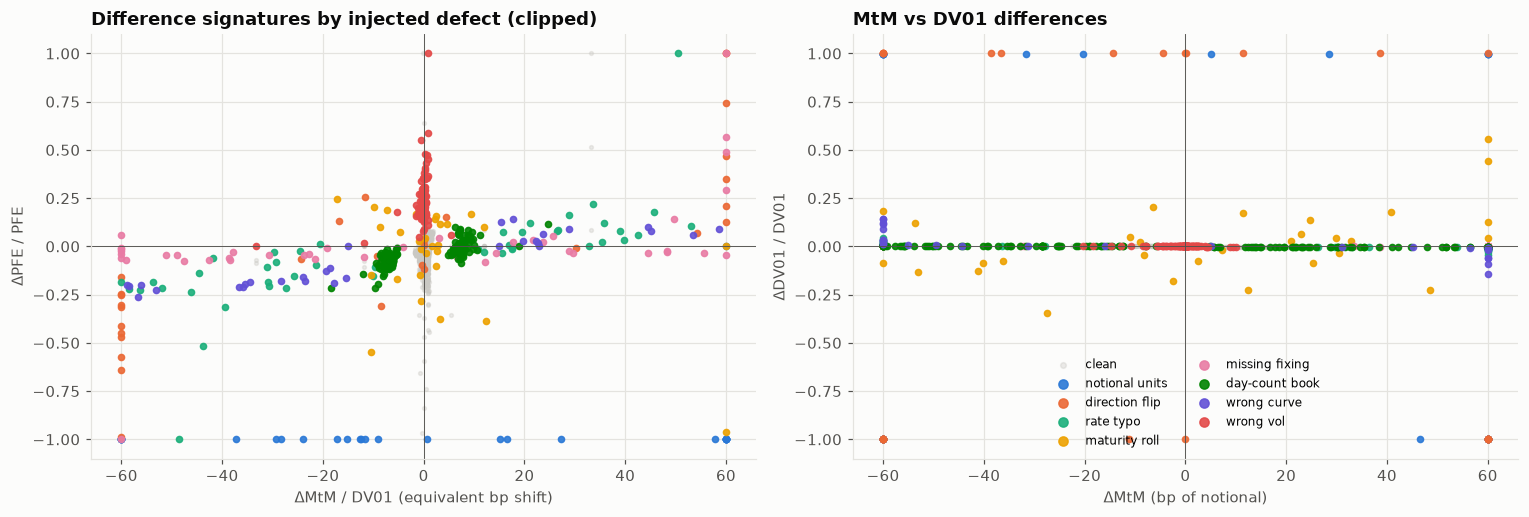

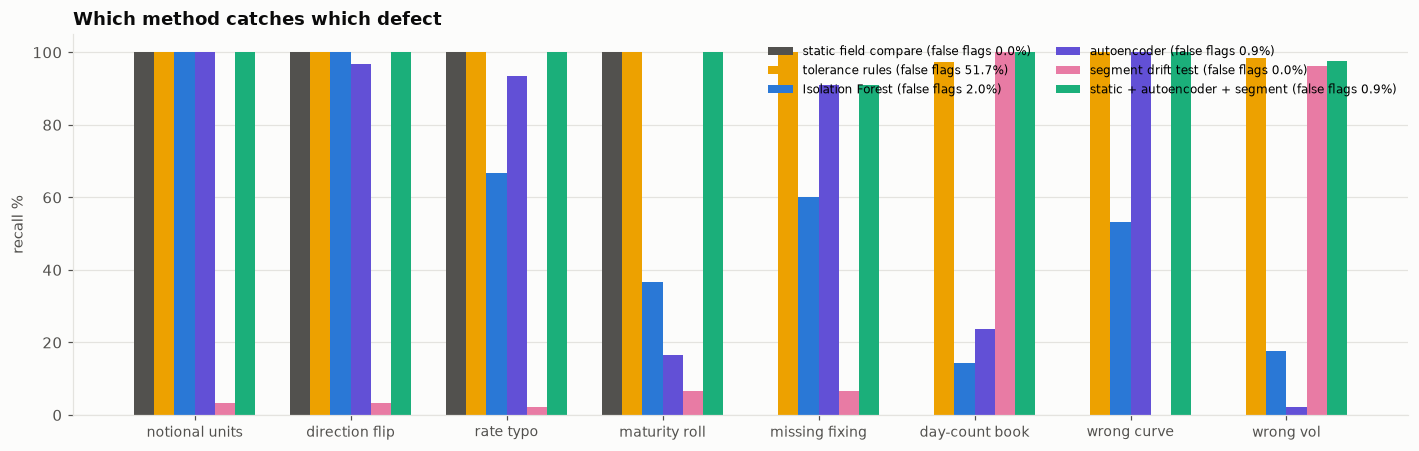

In [11]:
# --- Chart 1: difference signatures
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (xcol, ycol, xl, yl) in zip(
    axes,
    [
        (
            "d_mtm_in_dv01",
            "d_pfe_rel",
            "ΔMtM / DV01 (equivalent bp shift)",
            "ΔPFE / PFE",
        ),
        (
            "d_mtm_bp_notional",
            "d_dv01_rel",
            "ΔMtM (bp of notional)",
            "ΔDV01 / DV01",
        ),
    ],
):
    for d, color in DEFECT_COLORS.items():
        s = sig[recon["defect"] == d]
        ax.scatter(
            s[xcol].clip(-60, 60),
            s[ycol].clip(-1, 1),
            s=6 if d == "clean" else 16,
            color=color,
            alpha=0.35 if d == "clean" else 0.9,
            label=d,
        )
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
    ax.axhline(0, color=INK_2, lw=0.6)
    ax.axvline(0, color=INK_2, lw=0.6)
axes[0].set_title("Difference signatures by injected defect (clipped)")
axes[1].set_title("MtM vs DV01 differences")
axes[1].legend(fontsize=8, markerscale=1.5, ncol=2)
plt.tight_layout()
save_fig(fig, "01_difference_signatures")
plt.show()

# --- Chart 2: recall by defect type for each method
rec = scores[[c for c in scores.columns if c.startswith("recall · ")]].rename(
    columns=lambda c: c.replace("recall · ", "")
)
fig, ax = plt.subplots(figsize=(13, 4.2))
xp = np.arange(rec.shape[1])
for k, (m, color) in enumerate(
    zip(
        rec.index,
        [INK_2, PALETTE[3], PALETTE[0], PALETTE[6], PALETTE[4], PALETTE[2]],
    )
):
    ax.bar(
        xp + (k - 2.5) * 0.13,
        rec.loc[m],
        0.13,
        color=color,
        label=(
            f"{m} (false flags {scores.loc[m, 'false flags on clean %']:.1f}%)"
        ),
    )
ax.set_xticks(xp, rec.columns, fontsize=9)
ax.set_ylabel("recall %")
ax.set_title("Which method catches which defect")
ax.legend(fontsize=8, ncol=2)
ax.grid(axis="x", visible=False)
plt.tight_layout()
save_fig(fig, "02_recall_by_defect_and_method")
plt.show()

## 8. Root-cause clustering of flagged trades

A sign-off needs **explanations**, not just a list of 500 trades. Static breaks already come with their explanation (the field that differs). The valuation-only breaks are clustered on their difference signature, so trades that broke for the same reason end up together and an analyst investigates one representative per cluster. Cluster purity against the injected labels shows whether that works.

In [12]:
# Static breaks are already explained by the field compare: cluster the
# valuation-only breaks
flagged = recon[recon["flag_combined"] & ~recon["static_break"]].copy()
feat = pd.DataFrame({
    "mtm_bp": np.arcsinh(
        flagged["d_mtm"] / (flagged["notional_mm"] * 1e3) * 1e4
    ),
    "mtm_in_dv01": np.arcsinh(
        flagged["d_mtm"] / flagged["dv01_legacy"].abs().clip(lower=1e-3)
    ),
    "abs_mtm_in_dv01": np.arcsinh(flagged["abs_d_mtm_in_dv01"]),
    "dv01_rel": np.arcsinh(
        flagged["d_dv01"] / flagged["dv01_legacy"].abs().clip(lower=1e-3) * 10
    ),
    # asinh: keeps sign, tames gross outliers
    "pfe_rel": np.arcsinh(flagged["d_pfe_rel"] * 10),
})
N_CLUSTERS = 5
km = KMeans(n_clusters=N_CLUSTERS, n_init=20, random_state=SEED).fit(feat)
flagged["cluster"] = km.labels_
profile = flagged.groupby("cluster").agg(
    trades=("legacy_id", "count"),
    median_dMtM_bp_notional=(
        "d_mtm",
        lambda s: np.median(
            s / (flagged.loc[s.index, "notional_mm"] * 1e3) * 1e4
        ),
    ),
    median_dMtM_in_dv01=(
        "d_mtm",
        lambda s: np.median(
            s / flagged.loc[s.index, "dv01_legacy"].abs().clip(lower=1e-3)
        ),
    ),
    median_dPFE_rel=("d_pfe_rel", "median"),
    top_segment=(
        "book",
        lambda s: (
            f"{flagged.loc[s.index, 'counterparty'].mode()[0]} · {s.mode()[0]}"
        ),
    ),
    dominant_defect=("defect", lambda s: s.value_counts().index[0]),
    purity_pct=(
        "defect",
        lambda s: s.value_counts(normalize=True).iloc[0] * 100,
    ),
)
profile.sort_values("trades", ascending=False).round(2)

,trades,median_dMtM_bp_notional,median_dMtM_in_dv01,median_dPFE_rel,top_segment,dominant_defect,purity_pct
cluster,,,,,,,
2,123,0.00,0.00,0.23,Bank G · ALM hedges,wrong vol,98.37
1,105,-32.73,-7.13,-0.07,Bank D · Client swaps,day-count book,77.14
0,89,30.36,7.72,0.00,Bank C · Client swaps,day-count book,79.78
3,32,-264.49,-45.08,-0.07,Bank H · ALM hedges,missing fixing,62.50
4,24,262.57,44.76,0.04,Bank B · ALM hedges,missing fixing,62.50


## 9. Sign-off dashboard

In [13]:
# Status per book: red if any unexplained break remains, amber if only
# benign/tolerated differences
book_status = recon.groupby("book").agg(
    trades=("legacy_id", "count"),
    static=("static_break", "sum"),
    flagged=("flag_combined", "sum"),
    true_defects=("is_defect", "sum"),
)
book_status["status"] = np.where(
    book_status["flagged"] > 0, "open breaks", "ready for sign-off"
)
ns = (
    recon.groupby("counterparty")[
        ["pfe_legacy", "pfe_new", "mtm_legacy", "mtm_new"]
    ].sum()
    / 1e3
)

dash = make_subplots(
    rows=2,
    cols=2,
    vertical_spacing=0.16,
    horizontal_spacing=0.08,
    specs=[[{}, {}], [{"type": "table", "colspan": 2}, None]],
    subplot_titles=(
        "Recall by defect type: combined framework vs tolerance rules",
        "Sum of stand-alone PFE by counterparty: legacy vs new (USD mm)",
        "Detection methods scorecard",
    ),
)
for m, color in [
    ("tolerance rules", PALETTE[3]),
    ("static + autoencoder + segment", PALETTE[0]),
]:
    dash.add_trace(
        go.Bar(x=rec.columns, y=rec.loc[m], name=m, marker_color=color), 1, 1
    )
dash.add_trace(
    go.Bar(
        x=ns.index, y=ns["pfe_legacy"], name="legacy PFE", marker_color=INK_2
    ),
    1,
    2,
)
dash.add_trace(
    go.Bar(
        x=ns.index, y=ns["pfe_new"], name="new PFE", marker_color=PALETTE[6]
    ),
    1,
    2,
)
sc = scores[
    ["flagged", "precision %", "recall %", "false flags on clean %"]
].reset_index()
dash.add_trace(
    go.Table(
        header=dict(
            values=list(sc.columns),
            fill_color="#f1f0ec",
            font=dict(color=INK, size=12),
            align="left",
        ),
        cells=dict(
            values=[
                sc[c] if c == "method" else sc[c].round(1) for c in sc.columns
            ],
            fill_color=SURFACE,
            font=dict(color=INK_2, size=12),
            align="left",
        ),
    ),
    2,
    1,
)
pop = population.iloc[0]
dash.update_layout(
    height=860,
    width=1400,
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    font=dict(color=INK_2),
    barmode="group",
    legend=dict(orientation="h", y=1.08, x=0.0),
    margin=dict(t=150),
    title=dict(
        x=0.01,
        text=(
            "<b>Exposure-engine migration · parallel-run sign-off pack ·"
            f" {EVAL_DATE:%d %b %Y}</b><br>"
            "<span"
            f" style='font-size:13px;color:{INK_2}'>{int(pop.matched_one_to_one):,} matched"
            f" · {int(pop.missing_in_new)} missing in new · "
            f"{int(pop.duplicated_in_new)} duplicated ·"
            f" {int(recon['static_break'].sum())} static breaks · "
            f"{int((recon['flag_combined'] & ~recon['static_break']).sum())} valuation"
            f" breaks in {N_CLUSTERS} root-cause clusters · "
            "books ready for sign-off:"
            f" {(book_status['status'] == 'ready for sign-off').sum()}/{len(book_status)}</span>"
        ),
    ),
)
dash.update_yaxes(title_text="recall %", row=1, col=1)
save_dashboard(dash, "dashboard")
recon.to_csv(OUT_DIR / "reconciliation_detail.csv", index=False)
scores.to_csv(OUT_DIR / "detection_scores.csv")
profile.to_csv(OUT_DIR / "root_cause_clusters.csv")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 10. Reading the results and limitations

This is a simulated parallel run on the 16 October 2026 market: 2,975 matched trades, 483 of them with an injected defect.

**Population first.** The SQL outer join finds the 15 trades that were not migrated and the 10 duplicates before any valuation is compared.

**The static-data compare is perfect but partial.** It catches 100% of notional, direction, rate and maturity defects with no false flags, but it cannot see any valuation-only defect, which are a quarter of all defects here.

**Fixed tolerances drown the team.** They catch almost everything, but they also flag **52% of clean trades**. Most of these are PFE differences above 5% caused only by the two engines' different random numbers, plus some MtM differences from curve interpolation.

Precision is 27%, so three of every four investigations are wasted.

**Per-trade anomaly detection** (autoencoder: 91% precision, 0.9% false flags) finds the isolated valuation defects, such as missing fixings and the wrong discount curve, without any labels.

It misses mapping defects that hit a whole segment, because a hundred trades with the same signature form a cluster, not a set of outliers.

**The segment drift test** finds exactly those: the client-swap books of Banks C and D (day count) and Bank G's ALM book (volatility), with no false segments.

**Together** (static compare + autoencoder + segment test), the methods reach **96% precision and 99% recall**, with about 500 trades to investigate instead of about 1,800.

**Root-cause clusters** reduce the valuation breaks to a handful of signatures. Wrong-vol and day-count trades form pure clusters (the latter split into receivers and payers).

Missing fixings and wrong discount curves share a cluster, because both shift MtM without changing DV01. The analyst needs one more check, fixings against curve assignment, to tell them apart.

**Limitations**

- Both systems are simulated with the same model family. A real migration also faces model differences (for example, a different short-rate model), which shift the "benign" cloud but not the method.
- Defects are injected independently. Real migrations often have shared causes, such as one mapping table that is wrong for a whole desk; clustering helps exactly there.
- The contamination rate (8%) is a planning assumption. In practice it is set from the first days of the parallel run and revised as breaks are fixed.
- PFE is stand-alone per trade. Netting-set reconciliation and collateral add further layers in a real sign-off.

## References

### Finance and regulation

- Basel Committee on Banking Supervision. (2013). *Principles for effective risk data aggregation and risk reporting* (BCBS 239). Bank for International Settlements. https://www.bis.org/publ/bcbs239.htm
- Board of Governors of the Federal Reserve System. (2011). *Supervisory guidance on model risk management* (SR 11-7). https://www.federalreserve.gov/boarddocs/srletters/2011/sr1107.htm
- Hull, J., & White, A. (1990). Pricing interest-rate-derivative securities. *The Review of Financial Studies, 3*(4), 573–592. https://doi.org/10.1093/rfs/3.4.573
- Hagan, P. S., & West, G. (2006). Interpolation methods for curve construction. *Applied Mathematical Finance, 13*(2), 89–129. https://doi.org/10.1080/13504860500396032
- Gregory, J. (2020). *The xVA challenge: Counterparty risk, funding, collateral, capital and initial margin* (4th ed.). Wiley. https://doi.org/10.1002/9781119508991

### Machine learning and deep learning

- Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008). Isolation forest. In *Proceedings of the 2008 Eighth IEEE International Conference on Data Mining* (pp. 413–422). https://doi.org/10.1109/ICDM.2008.17
- Hinton, G. E., & Salakhutdinov, R. R. (2006). Reducing the dimensionality of data with neural networks. *Science, 313*(5786), 504–507. https://doi.org/10.1126/science.1127647
- Chandola, V., Banerjee, A., & Kumar, V. (2009). Anomaly detection: A survey. *ACM Computing Surveys, 41*(3), 1–58. https://doi.org/10.1145/1541880.1541882
- Raasveldt, M., & Mühleisen, H. (2019). DuckDB: An embeddable analytical database. In *Proceedings of the 2019 International Conference on Management of Data*. https://doi.org/10.1145/3299869.3320212